In [9]:
# 시각화용 기반 함수

import numpy as np
import matplotlib.pyplot as plt

 # (분포 그려주는 함수)
def plot_histogram(data_values, bin_width=100, figsize=(12,6), title=None):
    start = np.floor(data_values.min() / bin_width) * bin_width
    end = np.ceil(data_values.max() / bin_width) * bin_width
    bins = np.arange(start, end + bin_width, bin_width)

    counts, bin_edges = np.histogram(data_values, bins=bins)
    bin_labels = [f"{int(bin_edges[i])}~{int(bin_edges[i+1])}" for i in range(len(counts))]

    plt.figure(figsize=figsize)
    plt.bar(bin_labels, counts, width=0.8)
    plt.yscale('log')

    plt.xticks(rotation=45)
    plt.xlabel("Range")
    plt.ylabel("Count (Log scale)")
    plt.title(title if title else f"Distribution (Change Title)")
    plt.tight_layout()
    plt.show()

def plot_data(data, figsize=(20, 6), linewidth=0.3, title="Change Title"):
    plt.figure(figsize=figsize)
    plt.plot(data, linewidth=linewidth)
    plt.title(title)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [11]:
# 데이터 경로 (수업 제공 데이터는 저장소에 포함하지 않음 — README 참고)
# Colab에서 실행할 때는 아래 두 줄의 주석을 풀고 구글 드라이브를 연결하세요.
# from google.colab import drive
# drive.mount('/content/drive')
DATA_PATH = "../data/CNCnoise_1.csv"


In [12]:
# cnc 기본정보 확인하기

import pandas as pd
data = pd.read_csv(DATA_PATH)

print("df.head()")
print(data.head())

print("\ndata.shape:")
print(data.shape)

print("\ndata.describe()")
print(data.describe())

df.head()
   1911
0  1933
1  1901
2  1939
3  1914
4  1884

data.shape:
(634759, 1)

data.describe()
                1911
count  634759.000000
mean     1917.505471
std        55.417047
min       474.000000
25%      1911.000000
50%      1919.000000
75%      1929.000000
max      3352.000000


In [13]:
# CNC 기계 (정상 데이터/비정상 데이터) 분할
data_normal = data.iloc[150000:]     # 정상
data_abnormal = data.iloc[:150000]   # 비정상 포함

print(data_normal.shape)
print(data_abnormal.shape)

(484759, 1)
(150000, 1)


In [14]:
# 데이터 시각화
import matplotlib.pyplot as plt

# 전체 데이터 시각화
plot_data(data, figsize =(500,6), linewidth = 0.1) # 전체 데이터 (분포 자세하게)시각화

plot_data(data_normal, figsize =(10,6), linewidth = 0.02) #정상 데이터만 골라서 확인

plot_data(data_abnormal, figsize =(10,6), linewidth = 0.02) #비정상 데이터만 골라서 확인

Output hidden; open in https://colab.research.google.com to view.

In [15]:
# 결측치 확인
print(data.isnull().sum()) # 결측치 개수 : 0개

print("\n", data.isnull().values.any()) # False -> 결측치 없음

1911    0
dtype: int64

 False


In [16]:
# 각 구간별로 개수 확인용
import numpy as np

data_values = data.iloc[:, 0].values

start = np.floor(data_values.min() / 100) * 100
end = np.ceil(data_values.max() / 100) * 100

bins = np.arange(start, end + 100, 100)

counts, bin_edges = np.histogram(data_values, bins=bins)

for i in range(len(counts)):
    print(f"{int(bin_edges[i])} ~ {int(bin_edges[i+1])} : {counts[i]} 개")


400 ~ 500 : 4 개
500 ~ 600 : 1 개
600 ~ 700 : 1 개
700 ~ 800 : 4 개
800 ~ 900 : 7 개
900 ~ 1000 : 20 개
1000 ~ 1100 : 23 개
1100 ~ 1200 : 44 개
1200 ~ 1300 : 63 개
1300 ~ 1400 : 105 개
1400 ~ 1500 : 186 개
1500 ~ 1600 : 299 개
1600 ~ 1700 : 1371 개
1700 ~ 1800 : 15763 개
1800 ~ 1900 : 69717 개
1900 ~ 2000 : 519673 개
2000 ~ 2100 : 23332 개
2100 ~ 2200 : 3015 개
2200 ~ 2300 : 622 개
2300 ~ 2400 : 226 개
2400 ~ 2500 : 143 개
2500 ~ 2600 : 55 개
2600 ~ 2700 : 44 개
2700 ~ 2800 : 20 개
2800 ~ 2900 : 10 개
2900 ~ 3000 : 6 개
3000 ~ 3100 : 1 개
3100 ~ 3200 : 1 개
3200 ~ 3300 : 2 개
3300 ~ 3400 : 1 개


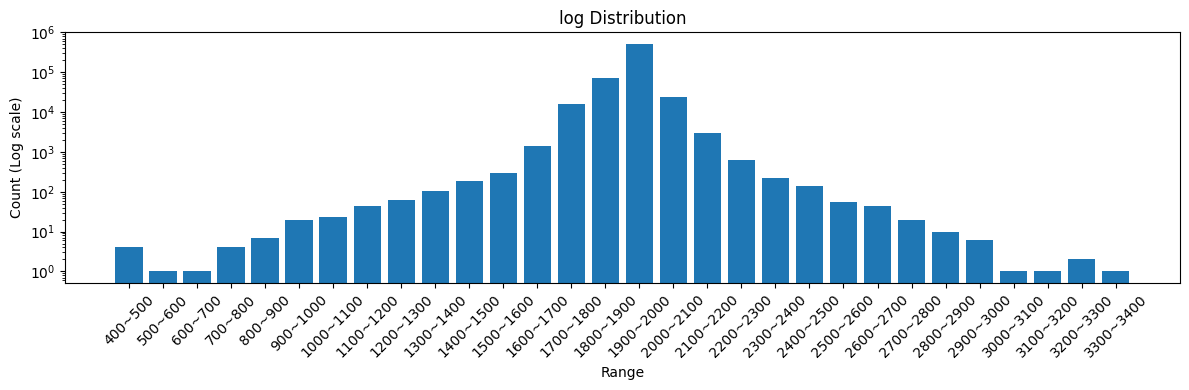

In [18]:
# log 스케일로 데이터 분포 확인
import numpy as np
import matplotlib.pyplot as plt

plot_histogram(data.values, bin_width = 100, figsize=(12,4),title = "log Distribution")

In [19]:
# lstm모델 전처리 (스케일링)
from sklearn.preprocessing import MinMaxScaler

# 학습 데이터 양 조절
raw_values = data_normal.iloc[:100000, 0].values  # 정상 데이터 10만개 학습시키기. numpy 배열로 변환

# 스케일링
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(raw_values.reshape(-1, 1)).flatten()

# LSTM 입력용으로 변환
window_size = 50
lstm_input = np.array([scaled_values[i:i+window_size] for i in range(len(scaled_values) - window_size)])
lstm_input = lstm_input.reshape((lstm_input.shape[0], window_size, 1))

# 입력 데이터 확인
print(lstm_input.shape) #(484709, 50, 1)

(99950, 50, 1)


In [1]:
# 모델 생성 - LSTM AutoEncoder

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense

inputs = Input(shape=lstm_input.shape[1:])
encoded = LSTM(64, activation='tanh')(inputs)
decoded = RepeatVector(window_size)(encoded)
decoded = LSTM(64, activation='tanh', return_sequences=True)(decoded)
outputs = TimeDistributed(Dense(1))(decoded)

model = Model(inputs, outputs)
model.compile(optimizer='adam', loss='mse')


NameError: name 'lstm_input' is not defined

In [24]:
model.fit(lstm_input, lstm_input, epochs=1, batch_size=32, validation_split=0.2)

3124/3124 ━━━━━━━━━━━━━━━━━━━━ 178s 55ms/step - loss: 0.0149


In [ ]:
import numpy as np

# 기존 reconstruction error 계산 (선택적)
# 꼭 비교 용도나 threshold 설정 위해 필요한 경우만 유지
# reconstructions = model(lstm_input, training=False).numpy()
# mse = np.mean(np.square(lstm_input - reconstructions), axis=(1, 2))

# 새로운 시계열 데이터 전처리
new_data = data.iloc[:, 0].values.reshape(-1, 1)
new_scaled = scaler.transform(new_data).reshape(-1)

# 슬라이딩 윈도우 입력 생성
new_seq = np.lib.stride_tricks.sliding_window_view(new_scaled, window_shape=window_size)
new_seq = new_seq.reshape((-1, window_size, 1))  # LSTM 입력 형태

# 모델 추론 및 MSE 계산
new_recon = model(new_seq, training=False).numpy()
new_mse = np.mean(np.square(new_seq - new_recon), axis=(1, 2))


In [ ]:

# 이상치 탐지

threshold = 0.5
anomalies = new_mse > threshold


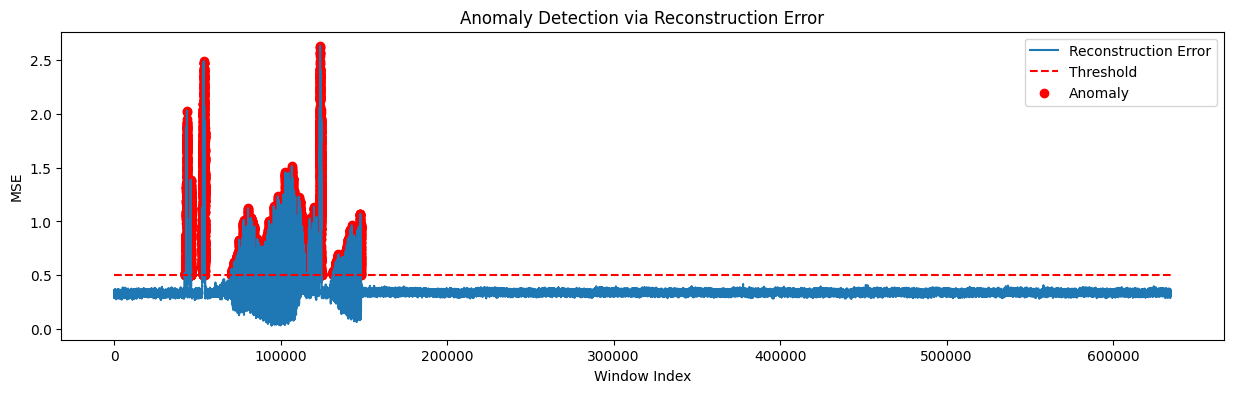

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 4))
plt.plot(new_mse, label='Reconstruction Error')
plt.hlines(threshold, xmin=0, xmax=len(new_mse), colors='r', linestyles='--', label='Threshold')
plt.scatter(np.where(anomalies)[0], new_mse[anomalies], color='red', label='Anomaly')
plt.legend()
plt.title("Anomaly Detection via Reconstruction Error")
plt.xlabel("Window Index")
plt.ylabel("MSE")
plt.show()


In [ ]:
import pandas as pd
import numpy as np
from scipy.io.wavfile import write
from IPython.display import Audio

# 데이터 읽기
data = pd.read_csv(DATA_PATH)
column = data.columns[0]
signal = data[column].values

# 정규화 (-1 ~ 1)
signal = signal.astype(np.float32)
signal = 2 * (signal - np.min(signal)) / (np.max(signal) - np.min(signal)) - 1

# int16 변환
signal_int16 = np.int16(signal * 32767)

# 샘플링 주파수 높게 설정
sample_rate = 44100  # 일반적인 고음질

# 데이터 길이 조절 (예: 처음 20000개 샘플) -> 전부
subset = signal_int16

# wav 파일 저장
output_path = "../data/CNC_noise.wav"
write(output_path, sample_rate, subset)

print(f"✅ WAV 파일 저장 완료: {output_path}")

# 바로 재생해보기
Audio(output_path)


✅ WAV 파일 저장 완료: /content/drive/MyDrive/Colab Notebooks/csv_files/CNC_noise.wav
